# Computer Vision and Pattern Recognition — Assignment & Quiz 2
## Brain MRI Image Classification using a Basic CNN from Scratch

**Course:** 01199 Computer Vision and Pattern Recognition [B] [FALL 26-27]  
**Task:** Binary image classification (Tumor vs No Tumor) using a CNN implemented from scratch.

**ID:** 23-50682-1

**Name:** Marufa Humaira

### Dataset source and justification
- **Dataset:** Brain Tumor MRI Dataset
- **Repository:** Mendeley Data, Version 1
- **DOI:** [10.17632/c9rt8d6zrf.1](https://doi.org/10.17632/c9rt8d6zrf.1)
- **Dataset page:** https://data.mendeley.com/datasets/c9rt8d6zrf/1
- **Creators:** Ahta Shamul Hoque Emran, Hafija Akter, Abdullah Al Shiam (2025)
- **Published dataset description:** 8,277 training images + 1,816 testing images = **10,093 MRI images**.
- **License:** CC BY 4.0.
- **Task labels described by the repository:** Tumor and No Tumor.

This dataset meets the assignment's minimum image-count requirement (2,000–2,500 images). The repository page identifies a downloadable ZIP of **176 MB**, which is below the 2–2.5 GB limit.

**Important academic note:** This notebook does not invent accuracy or other results. Run all cells to generate the actual metrics from the downloaded dataset. This is an educational image-classification exercise, not a medical diagnostic system.

## 1. Learning objectives
1. Load and inspect a real image dataset.
2. Preprocess images and create reproducible train/validation/test splits.
3. Implement a basic CNN architecture from scratch using PyTorch (no pretrained weights).
4. Train the CNN and monitor training/validation loss and accuracy.
5. Evaluate the model using accuracy, precision, recall, F1-score and a confusion matrix.
6. Discuss limitations and possible improvements.

## 2. Environment
Recommended: **Google Colab with GPU runtime**. CPU execution is also supported but may take longer.

In Google Colab: `Runtime → Change runtime type → T4 GPU` (if available).

In [1]:
# Install/import required libraries
!pip -q install torch torchvision scikit-learn matplotlib seaborn pandas pillow

import os, zipfile, random, shutil, pathlib, time, copy, collections, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_score, recall_score,
                             f1_score)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

PyTorch: 2.14.1+cu130
Device: cuda


## 3. Download the dataset

Download `Dataset.zip` (176 MB) from the official Mendeley Data page:

https://data.mendeley.com/datasets/c9rt8d6zrf/1

In Colab, run the next cell and upload the ZIP file. If running locally, set `ZIP_PATH` to the downloaded ZIP path. Do not upload a different dataset without updating the citation and methodology.

In [4]:
# Google Colab upload. If running locally, set ZIP_PATH manually instead.
ZIP_PATH = None

try:
    from google.colab import files
    uploaded = files.upload()  # Select the official Dataset.zip
    if uploaded:
        ZIP_PATH = next(iter(uploaded.keys()))
except ImportError:
    print("Not running in Google Colab. Set ZIP_PATH to your downloaded Dataset.zip file.")

if ZIP_PATH is None or not os.path.isfile(ZIP_PATH):
    raise FileNotFoundError(
        "Dataset ZIP not found. Download Dataset.zip from the official Mendeley page "
        "and upload it, or set ZIP_PATH to its local path."
    )

print("ZIP file:", ZIP_PATH)
print("ZIP size (MB):", round(os.path.getsize(ZIP_PATH) / (1024**2), 2))

Saving Dataset.zip to Dataset.zip
ZIP file: Dataset.zip
ZIP size (MB): 175.82


In [5]:
# Extract dataset
DATA_ROOT = "/content/brain_mri_dataset" if os.path.exists("/content") else "./brain_mri_dataset"
os.makedirs(DATA_ROOT, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(DATA_ROOT)

print("Extracted to:", DATA_ROOT)
for root, dirs, files_ in os.walk(DATA_ROOT):
    level = root.replace(DATA_ROOT, "").count(os.sep)
    if level <= 3:
        print("  " * level + os.path.basename(root) + f"  ({len(files_)} files)")

Extracted to: /content/brain_mri_dataset
brain_mri_dataset  (0 files)
  Dataset  (1 files)
    Testing  (0 files)
      tumor  (906 files)
      no tumor  (910 files)
    Training  (0 files)
      tumor  (4117 files)
      no tumor  (4160 files)


## 4. Dataset discovery and label preparation

The Mendeley page describes a binary task: **Tumor** and **No Tumor**. Some MRI archives store tumor subtypes in separate folders (for example, glioma, meningioma, pituitary), while a no-tumor folder may be named `notumor`, `no_tumor`, `normal`, or similar. The code below maps those folder names to the two required binary classes.

If the archive has a different folder naming convention, inspect the printed folders and adjust `NO_TUMOR_KEYWORDS` before continuing. This avoids silently assigning incorrect labels.

In [6]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
NO_TUMOR_KEYWORDS = {"no_tumor", "notumor", "no tumor", "normal", "healthy", "non_tumor", "nontumor"}

def is_no_tumor_folder(name):
    n = name.lower().replace("-", "_").replace(" ", "_")
    return any(k.replace(" ", "_") in n for k in NO_TUMOR_KEYWORDS)

image_records = []
folder_names = set()

for root, dirs, files_ in os.walk(DATA_ROOT):
    # Ignore hidden/system folders
    dirs[:] = [d for d in dirs if not d.startswith(".")]
    for fn in files_:
        if pathlib.Path(fn).suffix.lower() in IMAGE_EXTS:
            path = os.path.join(root, fn)
            parent = os.path.basename(root)
            folder_names.add(parent)
            label = 0 if is_no_tumor_folder(parent) else 1
            image_records.append((path, label, parent))

print("Image files found:", len(image_records))
print("Immediate image-containing folder names:", sorted(folder_names))
print("Binary label mapping: 0 = No Tumor, 1 = Tumor")
print("Counts:", collections.Counter(r[1] for r in image_records))

if len(image_records) < 2000:
    raise ValueError("Fewer than 2,000 images were found. Check that the complete official ZIP was extracted.")

labels_found = set(r[1] for r in image_records)
if labels_found != {0, 1}:
    raise ValueError("Both binary classes were not detected. Review folder names and label mapping.")

Image files found: 10093
Immediate image-containing folder names: ['no tumor', 'tumor']
Binary label mapping: 0 = No Tumor, 1 = Tumor
Counts: Counter({0: 5070, 1: 5023})


## 5. Verify labels and inspect sample images

Before training, inspect sample images and class counts. The folder-to-label mapping is an assumption based on folder names and must be checked against the dataset structure.

,source_folder,class_name,image_count
0,no tumor,No Tumor,5070
1,tumor,Tumor,5023


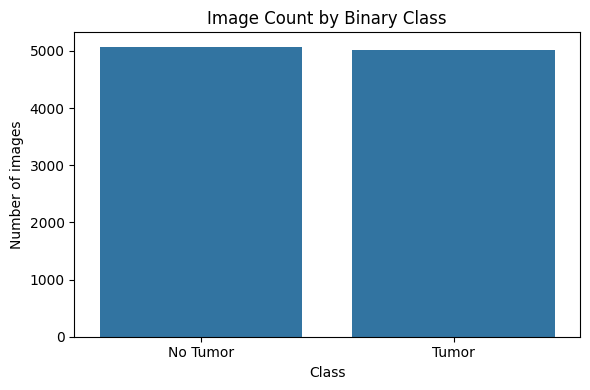

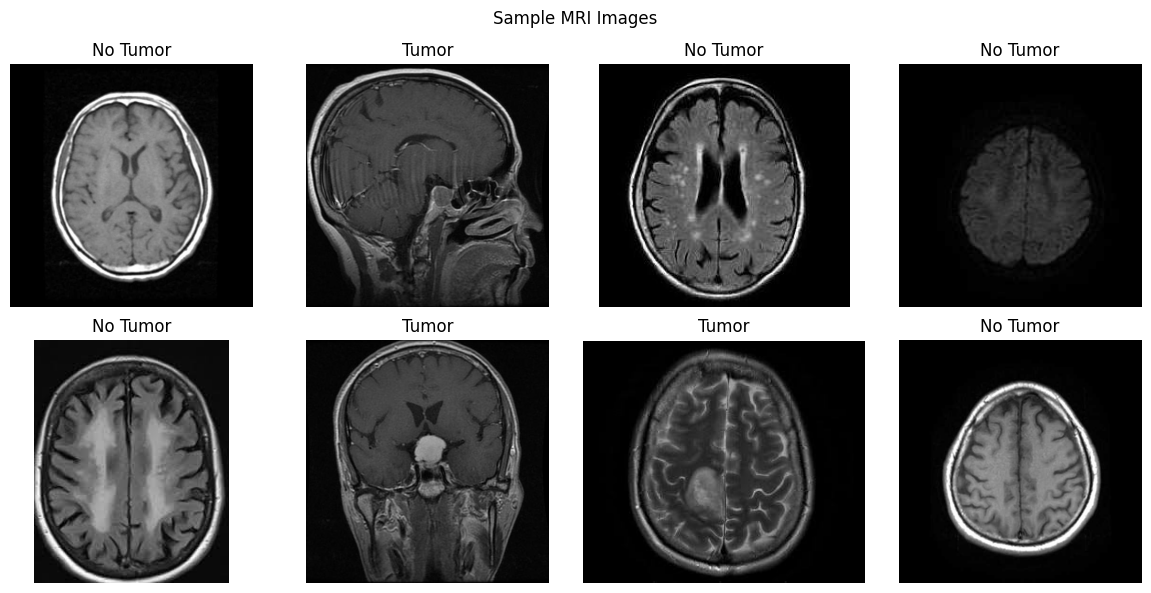

In [7]:
df = pd.DataFrame(image_records, columns=["path", "label", "source_folder"])
df["class_name"] = df["label"].map({0: "No Tumor", 1: "Tumor"})
display(df.groupby(["source_folder", "class_name"]).size().reset_index(name="image_count"))

plt.figure(figsize=(6,4))
sns.countplot(data=df, x="class_name", order=["No Tumor", "Tumor"])
plt.title("Image Count by Binary Class")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()

sample_df = df.sample(min(8, len(df)), random_state=SEED)
fig, axes = plt.subplots(2, 4, figsize=(12,6))
for ax, (_, row) in zip(axes.flat, sample_df.iterrows()):
    try:
        im = Image.open(row["path"]).convert("RGB")
        ax.imshow(im)
        ax.set_title(row["class_name"])
    except Exception as e:
        ax.set_title("Unreadable image")
    ax.axis("off")
plt.suptitle("Sample MRI Images")
plt.tight_layout()
plt.show()

## 6. Train/validation/test split

We use a stratified 70% / 15% / 15% split. Stratification preserves the approximate class proportions in each subset. A fixed random seed makes the split reproducible. The test set is kept separate until final evaluation.

In [8]:
paths = df["path"].tolist()
y = df["label"].astype(int).tolist()

train_paths, temp_paths, train_y, temp_y = train_test_split(
    paths, y, test_size=0.30, random_state=SEED, stratify=y
)
val_paths, test_paths, val_y, test_y = train_test_split(
    temp_paths, temp_y, test_size=0.50, random_state=SEED, stratify=temp_y
)

print(f"Total: {len(paths)}")
print(f"Train: {len(train_paths)} ({len(train_paths)/len(paths):.1%})")
print(f"Validation: {len(val_paths)} ({len(val_paths)/len(paths):.1%})")
print(f"Test: {len(test_paths)} ({len(test_paths)/len(paths):.1%})")

split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Images": [len(train_y), len(val_y), len(test_y)],
    "No Tumor": [train_y.count(0), val_y.count(0), test_y.count(0)],
    "Tumor": [train_y.count(1), val_y.count(1), test_y.count(1)]
})
display(split_summary)

Total: 10093
Train: 7065 (70.0%)
Validation: 1514 (15.0%)
Test: 1514 (15.0%)


,Split,Images,No Tumor,Tumor
0,Train,7065,3549,3516
1,Validation,1514,761,753
2,Test,1514,760,754


## 7. Image preprocessing and DataLoaders

All images are converted to RGB, resized to 128×128 pixels, and normalized to the [0,1] range. Light augmentation (horizontal flip and small rotation) is applied only to training images to improve generalization. Validation and test images are not augmented.

In [9]:
IMG_SIZE = 128
BATCH_SIZE = 32
NUM_WORKERS = 2 if os.name != "nt" else 0

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor()
])
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

class BrainMRIDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img = Image.open(self.image_paths[idx]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, torch.tensor(self.labels[idx], dtype=torch.long)

train_ds = BrainMRIDataset(train_paths, train_y, train_transform)
val_ds = BrainMRIDataset(val_paths, val_y, eval_transform)
test_ds = BrainMRIDataset(test_paths, test_y, eval_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

xb, yb = next(iter(train_loader))
print("Batch image tensor:", xb.shape)
print("Batch label tensor:", yb.shape)

Batch image tensor: torch.Size([32, 3, 128, 128])
Batch label tensor: torch.Size([32])


## 8. Basic CNN architecture from scratch

The model is built from standard convolutional layers, ReLU activations, max-pooling, dropout, and fully connected layers. It is initialized randomly and does **not** use transfer learning or pretrained weights.

| Block | Layers | Output channels |
|---|---|---:|
| 1 | Conv(3×3) + ReLU + MaxPool | 32 |
| 2 | Conv(3×3) + ReLU + MaxPool | 64 |
| 3 | Conv(3×3) + ReLU + MaxPool | 128 |
| Classifier | Adaptive average pool + Linear + Dropout + Linear | 2 |

The final layer returns two logits, one for each class. Cross-entropy loss internally applies the appropriate log-softmax operation.

In [10]:
class BasicCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.40),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = BasicCNN(num_classes=2).to(DEVICE)
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

# Verify output shape
with torch.no_grad():
    dummy = torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
    print("Output shape:", model(dummy).shape)  # Expected: [2, 2]

BasicCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): AdaptiveAvgPool2d(output_size=(4, 4))
    (1): Flatten(start_dim=1, end_dim=-1)
    (2): Linear(in_features=2048, out_features=128, bias=True)
    (3): ReLU(inplace=True)
    (4): Dropout(p=0.4, inplace=False)
    (5): Linear(in_features=128, out_features=2, bias=True)
  )
)
Total parameters: 355,778
Trainable parameters: 355,778
Output shape: torch.Size([2, 2

## 9. Model training

We use Adam optimizer and CrossEntropyLoss. The model checkpoint with the best validation accuracy is saved and restored before testing. Training/validation metrics are calculated after each epoch.

In [11]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
EPOCHS = 10

history = {
    "train_loss": [], "val_loss": [],
    "train_acc": [], "val_acc": []
}
best_val_acc = -1.0
best_state = None

def run_epoch(loader, training=False):
    model.train() if training else model.eval()
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            outputs = model(images)
            loss = criterion(outputs, labels)
            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * labels.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total

start_time = time.time()
for epoch in range(EPOCHS):
    train_loss, train_acc = run_epoch(train_loader, training=True)
    val_loss, val_acc = run_epoch(val_loader, training=False)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state = copy.deepcopy(model.state_dict())
        torch.save(best_state, "best_brain_mri_cnn.pth")

    print(f"Epoch [{epoch+1:02d}/{EPOCHS}] "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

elapsed = time.time() - start_time
print(f"Training time: {elapsed/60:.2f} minutes")
print(f"Best validation accuracy: {best_val_acc:.4f}")

if best_state is not None:
    model.load_state_dict(best_state)

Epoch [01/10] Train Loss: 0.3494 | Train Acc: 0.8493 | Val Loss: 0.2306 | Val Acc: 0.9062
Epoch [02/10] Train Loss: 0.1833 | Train Acc: 0.9325 | Val Loss: 0.1596 | Val Acc: 0.9406
Epoch [03/10] Train Loss: 0.1345 | Train Acc: 0.9567 | Val Loss: 0.1315 | Val Acc: 0.9531
Epoch [04/10] Train Loss: 0.1179 | Train Acc: 0.9608 | Val Loss: 0.1080 | Val Acc: 0.9643
Epoch [05/10] Train Loss: 0.1031 | Train Acc: 0.9645 | Val Loss: 0.1220 | Val Acc: 0.9498
Epoch [06/10] Train Loss: 0.0930 | Train Acc: 0.9677 | Val Loss: 0.1054 | Val Acc: 0.9551
Epoch [07/10] Train Loss: 0.0965 | Train Acc: 0.9650 | Val Loss: 0.0940 | Val Acc: 0.9663
Epoch [08/10] Train Loss: 0.0816 | Train Acc: 0.9718 | Val Loss: 0.0854 | Val Acc: 0.9676
Epoch [09/10] Train Loss: 0.0760 | Train Acc: 0.9707 | Val Loss: 0.1043 | Val Acc: 0.9683
Epoch [10/10] Train Loss: 0.0757 | Train Acc: 0.9741 | Val Loss: 0.0746 | Val Acc: 0.9736
Training time: 3.88 minutes
Best validation accuracy: 0.9736


## 10. Training performance visualization

The learning curves help identify convergence and possible overfitting. A widening gap between training and validation accuracy, or training loss decreasing while validation loss increases, can indicate overfitting.

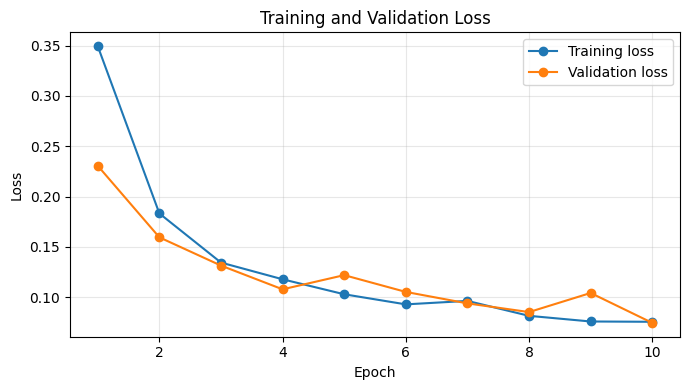

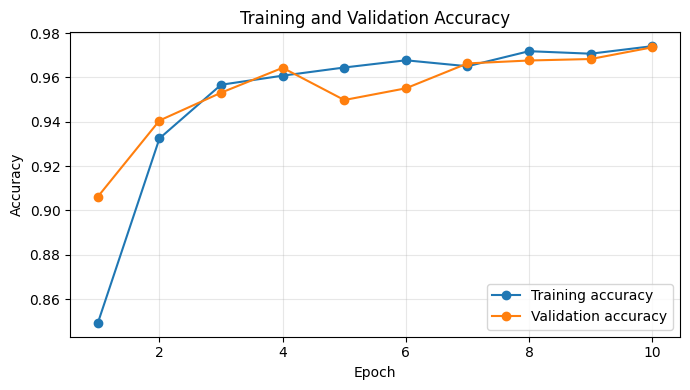

In [12]:
epochs_range = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(7,4))
plt.plot(epochs_range, history["train_loss"], marker="o", label="Training loss")
plt.plot(epochs_range, history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,4))
plt.plot(epochs_range, history["train_acc"], marker="o", label="Training accuracy")
plt.plot(epochs_range, history["val_acc"], marker="o", label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Final test-set evaluation

The test set is evaluated using the best validation checkpoint. We report accuracy, macro precision, macro recall, macro F1-score, a class-wise classification report, and a confusion matrix.

Test Accuracy       : 0.9749
Macro Precision     : 0.9750
Macro Recall        : 0.9749
Macro F1-score      : 0.9749

Classification Report:
              precision    recall  f1-score   support

    No Tumor       0.97      0.98      0.98       760
       Tumor       0.98      0.97      0.97       754

    accuracy                           0.97      1514
   macro avg       0.97      0.97      0.97      1514
weighted avg       0.97      0.97      0.97      1514



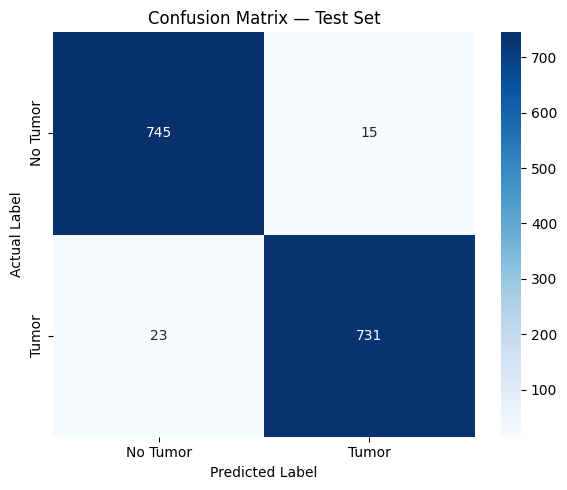

In [13]:
model.eval()
all_true, all_pred = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        outputs = model(images)
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_pred.extend(preds.tolist())
        all_true.extend(labels.numpy().tolist())

class_names = ["No Tumor", "Tumor"]
test_accuracy = accuracy_score(all_true, all_pred)
test_precision = precision_score(all_true, all_pred, average="macro", zero_division=0)
test_recall = recall_score(all_true, all_pred, average="macro", zero_division=0)
test_f1 = f1_score(all_true, all_pred, average="macro", zero_division=0)

print(f"Test Accuracy       : {test_accuracy:.4f}")
print(f"Macro Precision     : {test_precision:.4f}")
print(f"Macro Recall        : {test_recall:.4f}")
print(f"Macro F1-score      : {test_f1:.4f}")
print("\nClassification Report:")
print(classification_report(all_true, all_pred, target_names=class_names, zero_division=0))

cm = confusion_matrix(all_true, all_pred, labels=[0,1])
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix — Test Set")
plt.tight_layout()
plt.show()

## 12. Result analysis and discussion

After running the notebook, complete the interpretation using the actual output above.

- **Accuracy:** the proportion of all test images classified correctly.
- **Precision:** among images predicted as a class, how many truly belong to that class.
- **Recall:** among actual images of a class, how many the model correctly identifies.
- **F1-score:** harmonic mean of precision and recall.
- **Confusion matrix:** shows correct and incorrect predictions for each class.

### Discussion prompts
1. Did training accuracy improve across epochs?
2. Did validation loss generally decrease, or did it begin increasing?
3. Which class has lower recall? What does that mean for missed cases?
4. Does the confusion matrix show more false positives or false negatives?
5. Is the training/validation gap evidence of overfitting?

**Do not write a made-up explanation.** Use the generated metrics and plots to answer these questions. In a medical context, false negatives (tumor images predicted as no tumor) are particularly important, but this student model is not suitable for clinical use.

In [14]:
# Generate a compact results table for the report
results_table = pd.DataFrame({
    "Metric": ["Test Accuracy", "Macro Precision", "Macro Recall", "Macro F1-score",
               "Best Validation Accuracy", "Training Epochs", "Image Size"],
    "Value": [test_accuracy, test_precision, test_recall, test_f1,
              best_val_acc, EPOCHS, f"{IMG_SIZE}x{IMG_SIZE}"]
})
display(results_table)

results_table.to_csv("brain_mri_cnn_results.csv", index=False)
print("Saved: brain_mri_cnn_results.csv")

,Metric,Value
0,Test Accuracy,0.974901
1,Macro Precision,0.974972
2,Macro Recall,0.97488
3,Macro F1-score,0.974899
4,Best Validation Accuracy,0.97358
5,Training Epochs,10
6,Image Size,128x128


Saved: brain_mri_cnn_results.csv


## 13. Conclusion

This assignment implemented a basic convolutional neural network from scratch for binary classification of brain MRI images into Tumor and No Tumor. The workflow included dataset inspection, image resizing, data augmentation for training, stratified splitting, CNN training, and evaluation with standard classification metrics and a confusion matrix.

The final conclusion must be updated after execution with the measured test metrics. The experiment demonstrates a basic CNN workflow; it does not establish clinical diagnostic reliability. Further work could include more training data, careful duplicate/leakage checks, hyperparameter tuning, regularization, and external validation.

## 14. Limitations
- A relatively small CNN may not capture all complex MRI patterns.
- Results depend on dataset quality, class balance, and label correctness.
- Random splitting may not guarantee patient-level independence if multiple scans from the same patient exist.
- Augmentation and resizing can remove or alter useful details.
- Test performance on this dataset does not guarantee performance on images from other hospitals or scanners.
- This model must not be used for diagnosis or treatment decisions.

## 15. References
1. Emran, A. S. H., Akter, H., & Shiam, A. A. (2025). *Brain Tumor MRI Dataset*. Mendeley Data, Version 1. https://doi.org/10.17632/c9rt8d6zrf.1
2. PyTorch Documentation. https://pytorch.org/docs/stable/index.html
3. Scikit-learn Documentation. https://scikit-learn.org/stable/

## 16. Submission checklist
- [ ] Downloaded the official Mendeley dataset ZIP.
- [ ] Confirmed the extracted image count and class-folder mapping.
- [ ] Executed every notebook cell from top to bottom.
- [ ] Reviewed training/validation curves and confusion matrix.
- [ ] Updated the result analysis and conclusion using actual metrics.
- [ ] Saved the executed notebook (`.ipynb`) with outputs.
- [ ] Included the dataset DOI/source in the submission form.